# Q2 — CelebA UNet AE tests

Shape check and sample plots. Requires CelebA download (first run can be slow).

In [3]:
import torch
from model import UNetAE, add_gaussian_noise

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)

model = UNetAE(in_channels=3, base_ch=32).to(device)
x = torch.rand(2, 3, 64, 64, device=device)
y = model(x)
print('output shape:', tuple(y.shape))
print('params (M):', round(sum(p.numel() for p in model.parameters()) / 1e6, 3))
assert y.shape == x.shape
print('shape OK')

device: cpu
output shape: (2, 3, 64, 64)
params (M): 0.467
shape OK


Downloading...
From (original): https://drive.google.com/uc?id=0B7EVK8r0v71pZjFTYXZWM3FlRnM
From (redirected): https://drive.usercontent.google.com/download?id=0B7EVK8r0v71pZjFTYXZWM3FlRnM&confirm=t&uuid=5a10cd13-75ae-4c73-9c36-51dd65a1a16b
To: d:\1. PhD Presentations\ADL-2026\advanced-deep-learning\open_assessment_two\question_two\data\celeba\img_align_celeba.zip
100%|██████████| 1.44G/1.44G [00:59<00:00, 24.4MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7EVK8r0v71pblRyaVFSWGxPY0U
To: d:\1. PhD Presentations\ADL-2026\advanced-deep-learning\open_assessment_two\question_two\data\celeba\list_attr_celeba.txt
100%|██████████| 26.7M/26.7M [00:02<00:00, 10.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1_ee_0u7vcNLOfNLegJRHmolfH5ICW-XS
To: d:\1. PhD Presentations\ADL-2026\advanced-deep-learning\open_assessment_two\question_two\data\celeba\identity_CelebA.txt
100%|██████████| 3.42M/3.42M [00:00<00:00, 8.87MB/s]
Downloading...
From: https://drive.google.com/uc?id=0B7E

test size: 19962


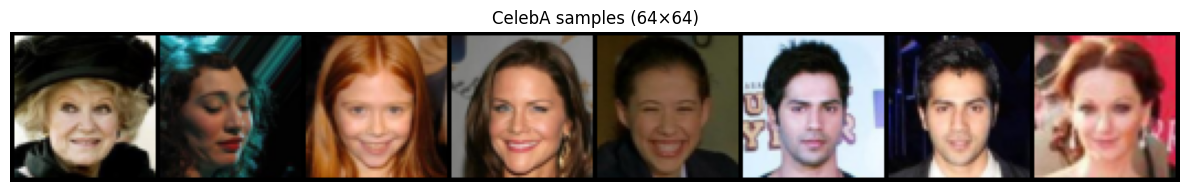

In [4]:
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torchvision.utils import make_grid

tfm = transforms.Compose([
    transforms.Resize(64),
    transforms.CenterCrop(64),
    transforms.ToTensor(),
])
ds = datasets.CelebA('./data', split='test', download=True, transform=tfm)
print('test size:', len(ds))

n = 8
imgs = torch.stack([ds[i][0] for i in range(n)])
grid = make_grid(imgs, nrow=n, padding=2)
plt.figure(figsize=(12, 2))
plt.imshow(grid.permute(1, 2, 0))
plt.title('CelebA samples (64×64)')
plt.axis('off')
plt.tight_layout()
plt.savefig('plot_celeba_original.png', dpi=150, bbox_inches='tight')
plt.show()